# metaspace_ml: фазовая ML-библиотека

**Практическое продолжение** научной реконструкции v8. Это не «метафизический движок» и не обещание, что комплексные сети лучше вещественных. Это набор инструментов, которые:

* делают фазовую структуру данных явной;
* измеряют когерентность $K$, энтропию $S_R$, ёмкость $C$ и эффективную размерность $D_{\mathrm{eff}}$ представлений;
* добавляют регуляризаторы на основе этих величин;
* заменяют некалиброванный $\chi$-порог статистически корректным отбором признаков (BH, перестановки, MDL);
* дают воспроизводимые бенчмарки, где видно, что работает, а что нет.

**Главный практический результат:** глобальный фазовый сдвиг — это помеха; признаки $z_i\bar z_j$ инвариантны к нему, а «сырые» $\operatorname{Re}z,\operatorname{Im}z$ — нет. Выигрыш даёт калибровочная инвариантность, а не комплексность сама по себе.


In [1]:
import sys
import pathlib

ROOT = pathlib.Path.cwd()
while not (ROOT / "metaspace_ml").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression

import metaspace_ml as mml

mml.set_seed(0)
plt.rcParams["figure.max_open_warning"] = 0
print("metaspace_ml", mml.__version__)
print("torch", torch.__version__)
print("root", ROOT)


metaspace_ml 0.1.0
torch 2.10.0+cpu
root C:\Users\afina\OneDrive\Dokumenty\deepseek-harness\default-workspace


## 1. Задача с фазовым градиентом

Класс $c$ задаёт градиент фазы $c\cdot0.9\cdot j$ по признакам $j$. Глобальный фазовый сдвиг $\rho$ одинаков для всех признаков и классов; относительные фазы от него не зависят. Тест содержит четыре условия: чистые данные, глобальный сдвиг, фазовый шум и их комбинацию.


In [2]:
task = mml.PhaseGradientTask(n_features=8, n_classes=3, phase_step=0.9, template_seed=0)
z, y = task.sample(2000, phase_noise=0.2, seed=10)
ztr, zte, ytr, yte = mml.train_test_split_complex(z, y, test_size=0.3, seed=1)

conditions = {
    "clean": zte,
    "global phase": mml.add_global_phase(zte, seed=2),
    "phase noise 0.8": mml.add_phase_noise(zte, 0.8, seed=3),
    "global + noise": mml.add_phase_noise(mml.add_global_phase(zte, seed=4), 0.8, seed=5),
}
print("train", ztr.shape, "test", zte.shape)


train (1400, 8) test (600, 8)


## 2. Сырые признаки против фазовых разностей

`PhaseDifferenceFeatures` возвращает вещественные и мнимые части всех произведений $z_i\bar z_j$. Это точная реализация калибровочной инвариантности: глобальный сдвиг фазы умножает каждое $z_i$ на $e^{i\rho}$, а произведение $z_i\bar z_j$ — на $e^{i\rho}e^{-i\rho}=1$.


In [3]:
def raw(z):
    return np.concatenate([z.real, z.imag], axis=1)

phase_features = mml.PhaseDifferenceFeatures().fit(ztr)

models = {
    "real logistic (raw)": (
        LogisticRegression(max_iter=3000).fit(raw(ztr), ytr),
        raw,
    ),
    "phase-diff + logistic": (
        LogisticRegression(max_iter=3000).fit(phase_features.transform(ztr), ytr),
        phase_features.transform,
    ),
    "complex perceptron (raw)": (
        mml.MetaPerceptron(epochs=250, lr=0.05, random_state=0).fit(ztr, ytr),
        lambda v: v,
    ),
    "complex perceptron (phase-diff)": (
        mml.MetaPerceptron(epochs=250, lr=0.05, random_state=0).fit(
            phase_features.transform(ztr), ytr
        ),
        phase_features.transform,
    ),
}

table = {}
for name, (model, features) in models.items():
    table[name] = {cond: float(model.score(features(v), yte)) for cond, v in conditions.items()}

print(f"{'model':34s}" + "".join(f"{c:>20s}" for c in conditions))
for name, scores in table.items():
    print(f"{name:34s}" + "".join(f"{scores[c]:>20.3f}" for c in conditions))


model                                            clean        global phase     phase noise 0.8      global + noise
real logistic (raw)                              1.000               0.463               0.987               0.472
phase-diff + logistic                            1.000               1.000               0.973               0.982
complex perceptron (raw)                         1.000               0.447               0.982               0.463
complex perceptron (phase-diff)                  1.000               1.000               0.973               0.980


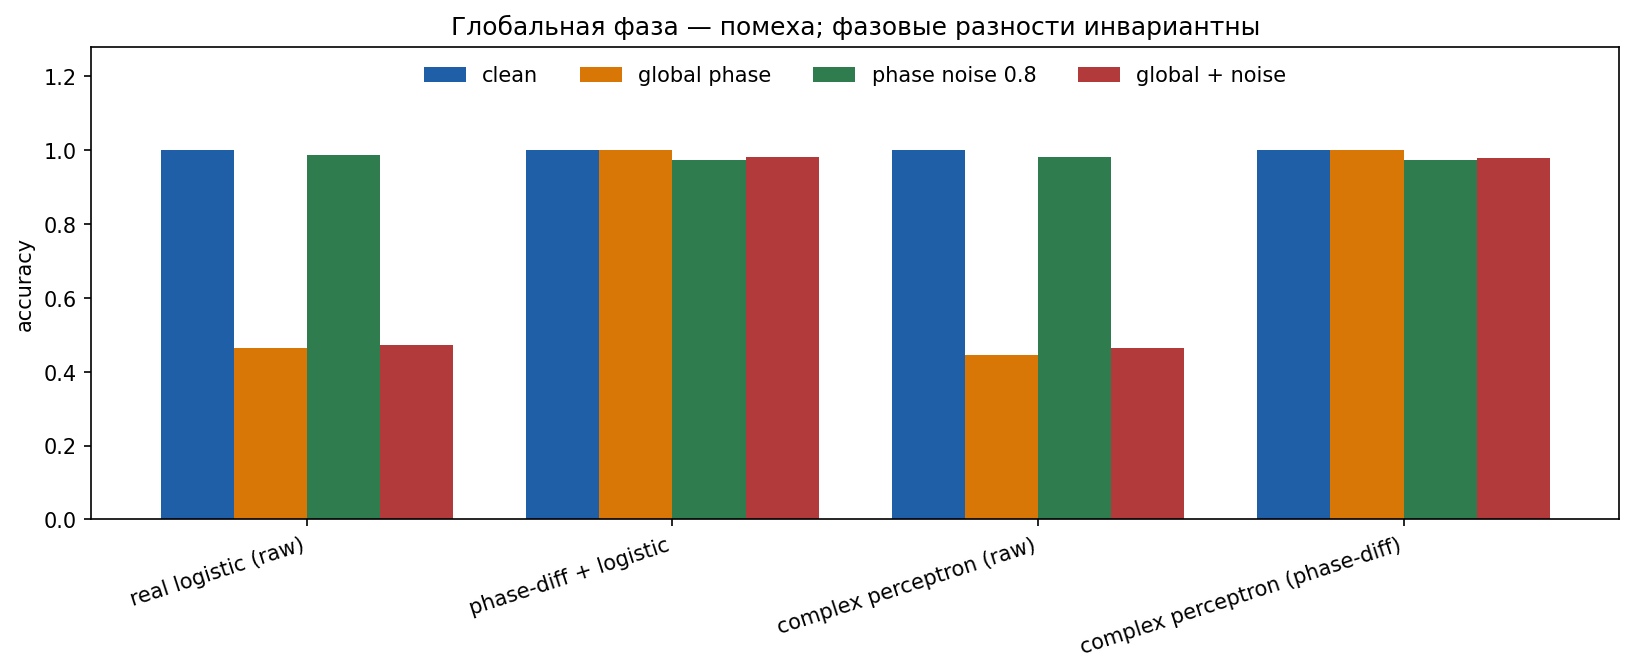

In [4]:
labels = list(models)
x = np.arange(len(labels))
width = 0.2
fig, ax = plt.subplots(figsize=(11.0, 4.6))
colors = ["#1f5fa8", "#d97706", "#2f7d4f", "#b23a3a"]
for i, cond in enumerate(conditions):
    ax.bar(x + (i - 1.5) * width, [table[n][cond] for n in labels], width,
           label=cond, color=colors[i])
ax.set_xticks(x, labels, rotation=18, ha="right")
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1.28)
ax.set_title("Глобальная фаза — помеха; фазовые разности инвариантны")
ax.legend(frameon=False, ncol=4, loc="upper center")
fig.tight_layout()


**Рис. 1.** Сырая вещественная логистическая регрессия и комплексный перцептрон на сырых $z$ падают до уровня случайного угадывания (≈0.46) при глобальном сдвиге фазы. Фазовые разности сохраняют точность 1.000. Комплексность сама по себе не помогает: комплексный линейный слой на сырых $z$ эквивалентен вещественному на $[\operatorname{Re}z,\operatorname{Im}z]$.


## 3. Комплексная модель и регуляризаторы

`MetaPerceptron` — комплексный линейный классификатор; `ComplexMLPClassifier` — комплексный MLP с ModReLU. Регуляризаторы `MetaspaceRegularizer` управляют геометрией скрытого представления: `coherence` повышает $K$ и снижает $C$, `capacity` штрафует $C$, `balance` штрафует отклонение от $\mu=\nu$.


In [5]:
clf = mml.ComplexMLPClassifier(hidden_dims=(16,), epochs=150, lr=0.03, random_state=0).fit(ztr, ytr)
clf_coh = mml.ComplexMLPClassifier(
    hidden_dims=(16,), epochs=150, lr=0.03, coherence=0.1, random_state=0
).fit(ztr, ytr)

with torch.no_grad():
    h = clf.model_.hidden(torch.as_tensor(zte, dtype=torch.complex64)).numpy()
    h_coh = clf_coh.model_.hidden(torch.as_tensor(zte, dtype=torch.complex64)).numpy()

print("без регуляризации:", {k: round(v, 3) for k, v in mml.representation_report(h).items()})
print("coherence=0.1:    ", {k: round(v, 3) for k, v in mml.representation_report(h_coh).items()})
print("accuracy:", round(clf.score(zte, yte), 3), "vs", round(clf_coh.score(zte, yte), 3))


без регуляризации: {'coherence': 0.286, 'entropy': 2.351, 'capacity': 0.411, 'effective_dimension': 8.676}
coherence=0.1:     {'coherence': 0.979, 'entropy': 2.235, 'capacity': 0.035, 'effective_dimension': 7.45}
accuracy: 1.0 vs 1.0


Регуляризатор действительно меняет геометрию: $K$ скрытого слоя растёт, $C$ падает. Различия в точности на одном seed малы; это не доказательство пользы, а иллюстрация того, что регуляризатор работает как заявлено. Для вывода нужен многократный эксперимент с доверительными интервалами.


## 4. Калиброванный отбор признаков

Наивный порог по выборочному выигрышу выбирает шум. `CalibratedFeatureSelector` заменяет его на BH, перестановочный максимум или MDL. Ниже — короткий прогон (50 реализаций), показывающий направление эффекта.


naive top-10       precision=0.194 recall=0.970 FDR=0.806
BH q=0.1           precision=0.857 recall=0.770 FDR=0.103
permutation max    precision=0.858 recall=0.640 FDR=0.042
MDL/BIC            precision=0.229 recall=0.990 FDR=0.771


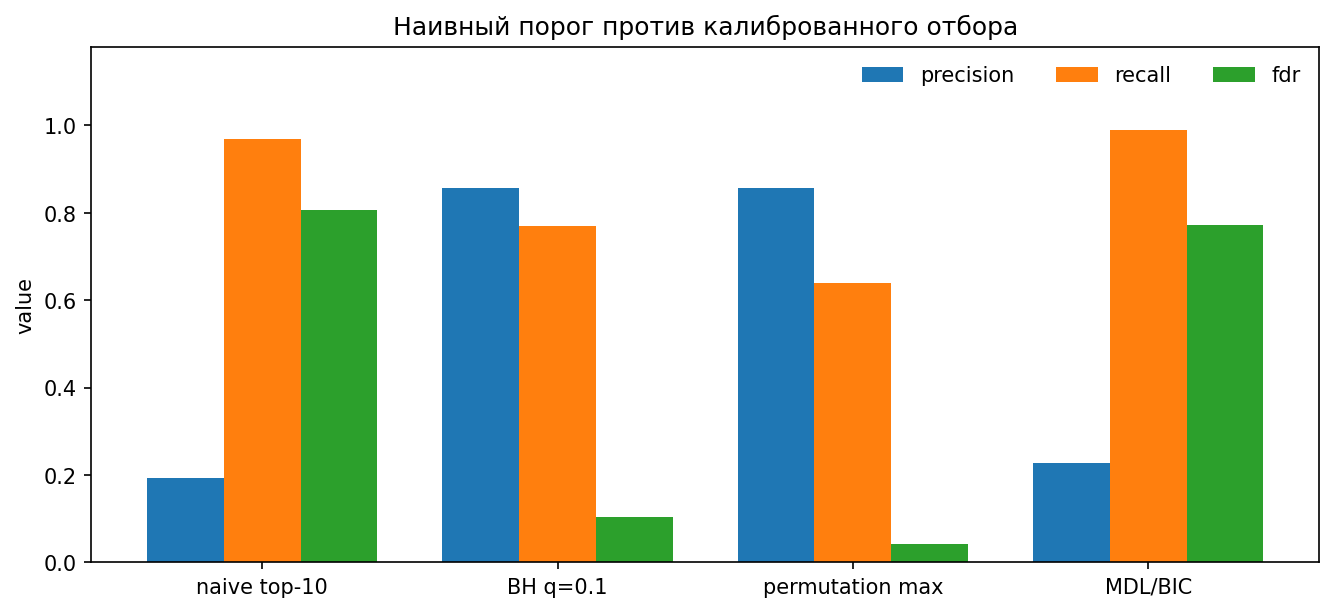

In [6]:
n, p, k, effect, reps = 100, 200, 2, 0.45, 50
rng = np.random.default_rng(0)
methods = {
    "naive top-10": dict(method="naive", top_m=10),
    "BH q=0.1": dict(method="bh", q=0.1),
    "permutation max": dict(method="permutation", alpha=0.05, n_permutations=200),
    "MDL/BIC": dict(method="mdl"),
}
acc = {name: {"precision": [], "recall": [], "fdr": []} for name in methods}
for rep in range(reps):
    X = rng.normal(size=(n, p))
    truth = np.zeros(p, dtype=bool)
    truth[rng.choice(p, k, replace=False)] = True
    beta = np.zeros(p); beta[truth] = effect
    yy = X @ beta + rng.normal(size=n)
    for name, kwargs in methods.items():
        params = dict(kwargs)
        method = params.pop("method")
        sel = mml.CalibratedFeatureSelector(method=method, random_state=rep, **params).fit(X, yy)
        mask = np.zeros(p, dtype=bool); mask[sel.get_support()] = True
        tp = int((mask & truth).sum()); fp = int((mask & ~truth).sum()); fn = int((~mask & truth).sum())
        acc[name]["precision"].append(mml.precision(tp, fp))
        acc[name]["recall"].append(mml.recall(tp, fn))
        acc[name]["fdr"].append(mml.fdr(fp, tp))

summary = {name: {key: float(np.mean(v)) for key, v in data.items()} for name, data in acc.items()}
for name, row in summary.items():
    print(f"{name:18s} precision={row['precision']:.3f} recall={row['recall']:.3f} FDR={row['fdr']:.3f}")

labels = list(summary)
x = np.arange(len(labels))
width = 0.26
fig, ax = plt.subplots(figsize=(9.0, 4.2))
for i, metric in enumerate(["precision", "recall", "fdr"]):
    ax.bar(x + (i - 1) * width, [summary[n][metric] for n in labels], width, label=metric)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.18)
ax.set_ylabel("value")
ax.set_title("Наивный порог против калиброванного отбора")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()


**Рис. 2.** Наивный top-10 даёт высокий recall, но precision около 0.2 и FDR около 0.8: большая часть отобранных признаков — шум. BH и перестановочный максимум снижают FDR до 0.10 и 0.04 соответственно. MDL/BIC в этой задаче FDR не контролирует.


## 5. Ограничения

1. Комплексный линейный слой с вещественным readout **не даёт дополнительной выразительности** по сравнению с вещественным слоем на $[\operatorname{Re}z,\operatorname{Im}z]$.
2. `PhaseDifferenceFeatures` растёт как $O(d^2)$; для больших $d$ нужен отбор или ядерные приближения.
3. Глобальная фаза должна быть действительно помехой. Если она несёт информацию, инвариантные признаки её потеряют.
4. BH требует корректных $p$-значений и условий зависимости; перестановки — обмениваемости при нуле.
5. Регуляризаторы — экспериментальный инструмент; нет универсального рецепта.
6. Библиотека не утверждает, что «метапространство» существует физически. Она реализует измеримые величины и проверяемые процедуры из меморандума.

**Документация:** `docs/ml_library.md`. **Тесты:** `python tests/test_ml.py` (26 тестов).
